# Fig. 8d: phonons and vibrational entropy

This notebook reproduces Fig. 8d of the DefectNet paper: the $\Gamma$-point phonon density of states
(DOS) of pristine CdSe$_{0.06}$Te$_{0.94}$ and of the 216-atom cell with the Bi$_{Cd}$ + Bi$_{Se}$ complex, and the
vibrational entropy of the complex in its five charge states relative to the pristine cell. It takes about
an hour on one NVIDIA A100 GPU.

Open this notebook from the `examples/paper/` folder of the repository. The DFT data it needs are in `data/` as
Apache Arrow tables (see `README.md` in this folder for the columns), and the model is the `DefectNet-v1.0.pt` weights file
of the v1.0 release.

## Install and download the model

The cell below installs TACE at commit `057e463` with the patch in `patches/`, the DefectNet package and `pyarrow`,
skipping every step that is already done. Install PyTorch for your machine first (pytorch.org). The weights
(`DefectNet-v1.0.pt`, 891 MB) are downloaded with the GitHub command-line tool unless a copy is already here or in
`examples/`.

In [1]:
%%bash
cd ../..                                         # repository root
if python -c "import tace" 2>/dev/null; then echo "TACE is already installed"
else
  git clone -q https://github.com/xvzemin/tace.git ../tace
  git -C ../tace checkout -q 057e463
  git -C ../tace apply "$PWD/patches/tace-057e463.patch"
  pip install -q -e ../tace
fi
python -c "import defectnet" 2>/dev/null && echo "DefectNet is already installed" || pip install -q -e .
python -c "import pyarrow" 2>/dev/null && echo "pyarrow is already installed" || pip install -q pyarrow
cd examples/paper
if [ -f DefectNet-v1.0.pt ]; then echo "DefectNet-v1.0.pt is already here"
elif [ -f ../DefectNet-v1.0.pt ]; then ln -s ../DefectNet-v1.0.pt . && echo "using ../DefectNet-v1.0.pt"
else gh release download v1.0 -R msehabibur/DefectNet -p DefectNet-v1.0.pt; fi

TACE is already installed


DefectNet is already installed


pyarrow is already installed


DefectNet-v1.0.pt is already here


## Load the model and the data

Every row of an Arrow table is one DFT calculation. `atoms(row)` builds the ASE structure the benchmark started from
(the DFT input geometry of a defect cell, the DFT final geometry of a pristine cell), and `seed(row)` is the random
seed of its rattle, the CRC32 checksum of the row's `path`, so a relaxation here starts from exactly the same
displaced atoms as in the paper. GPU arithmetic is not bit-for-bit reproducible across devices, so energies can
differ from the paper values by a few meV.

In [2]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)                 # hides TACE's start-up notes

import zlib
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.feather as feather
from ase import Atoms

import defectnet as dn


def table(name):
    return feather.read_table(f"data/{name}.arrow").to_pylist()


def atoms(row, positions="start_positions"):
    return Atoms(row["start_symbols"], positions=row[positions], cell=row["start_cell"], pbc=True)


def seed(row):
    return zlib.crc32(row["path"].encode())


calc = dn.load("DefectNet-v1.0.pt", functional="PBEsol")
cells = table("fig6a_cells")
pristine = {r["path"]: r for r in table("pristine_pbesol")}
print(len(cells), "defect cells and", len(pristine), "pristine cells, PBEsol")

172 defect cells and 15 pristine cells, PBEsol


## Force constants by finite differences

Each cell is relaxed as in the benchmark (rattled DFT geometry, FIRE to 0.02 eV/Å), then with LBFGS to
0.002 eV/Å. Every atom is displaced by $h = \pm 0.01$ Å along each Cartesian axis, without symmetry (the alloy has
none), and the force constants are the central differences

$$\Phi_{i\alpha, j\beta} = -\frac{F_{j\beta}(+h\,\hat e_{i\alpha}) - F_{j\beta}(-h\,\hat e_{i\alpha})}{2h}.$$

That is $2 \times 3 \times 216 = 1296$ force calls per cell.

In [3]:
from ase.optimize import LBFGS


def force_constants(r):
    a = dn.relax(atoms(r), calc, q=r.get("q", 0), seed=seed(r))
    LBFGS(a, logfile=None).run(fmax=0.002, steps=3000)
    p0, h = a.positions.copy(), 0.01
    fc = np.zeros((3 * len(a), 3 * len(a)))
    for i in range(len(a)):
        for k in range(3):
            f = []
            for s in (1, -1):
                a.positions = p0
                a.positions[i, k] += s * h
                f.append(a.get_forces().ravel())
            fc[3 * i + k] = -(f[0] - f[1]) / (2 * h)
    a.positions = p0
    return fc, a


cpx = {r["q"]: r for r in cells if r["path"].startswith("DFT/defect/PBEsol/CdSe0.06Te0.94/Bi_Cd+Bi_Se/")}
P = pristine[cpx[0]["pristine"]]
FC = {"pristine": force_constants(P)}
for q in sorted(cpx, reverse=True):
    FC[q] = force_constants(cpx[q])
    print(f"q = {q:+d} done")

q = +2 done


q = +1 done


q = +0 done


q = -1 done


q = -2 done


## Modes

The force constants are symmetrized, the acoustic sum rule is imposed on the self terms,
$\Phi_{i\alpha, i\beta} = -\sum_{j \ne i} \Phi_{i\alpha, j\beta}$, and the mode energies come from the dynamical
matrix $D = \Phi_{i\alpha, j\beta}/\sqrt{m_i m_j}$, with $\hbar\omega_k = \hbar\sqrt{\lambda_k}$ for each eigenvalue
$\lambda_k$ (in eV/(amu Å$^2$), so $\hbar = 0.0646541$ eV amu$^{1/2}$ Å eV$^{-1/2}$). The weight of mode $k$ on atom
$i$ is $|\mathbf e_{k,i}|^2$, used for the part of the DOS on the two Bi atoms.

In [4]:
HW = 0.0646541


def modes(fc, a):
    n, m = len(a), a.get_masses()
    fc = 0.5 * (fc + fc.T)
    B = fc.reshape(n, 3, n, 3)
    for i in range(n):
        B[i, :, i, :] -= B[i].sum(axis=1)
    fc = 0.5 * (B.reshape(3 * n, 3 * n) + B.reshape(3 * n, 3 * n).T)
    mm = np.repeat(m, 3)
    w2, v = np.linalg.eigh(fc / np.sqrt(np.outer(mm, mm)))
    return np.sign(w2) * HW * np.sqrt(np.abs(w2)), (v ** 2).reshape(n, 3, -1).sum(1)


W = {k: modes(*v) for k, v in FC.items()}
for k, (w, _) in W.items():
    print(f"{str(k):9s} highest mode {1e3 * w.max():.1f} meV, imaginary modes {(w < -5e-4).sum()}")
print("paper: highest pristine mode 21.1 meV, no imaginary modes")

pristine  highest mode 21.1 meV, imaginary modes 0
2         highest mode 21.6 meV, imaginary modes 0
1         highest mode 21.5 meV, imaginary modes 0
0         highest mode 21.5 meV, imaginary modes 0
-1        highest mode 21.5 meV, imaginary modes 0
-2        highest mode 21.4 meV, imaginary modes 0
paper: highest pristine mode 21.1 meV, no imaginary modes


## DOS and vibrational entropy

The DOS is a sum of Gaussians of width 0.5 meV over the modes. The vibrational entropy of a cell is

$$S_{vib} = k_B \sum_k \Big[\frac{x_k}{e^{x_k} - 1} - \ln\big(1 - e^{-x_k}\big)\Big], \qquad x_k = \frac{\hbar\omega_k}{k_BT},$$

and $\Delta S_{vib} = S_{vib}(\text{defect cell}) - S_{vib}(\text{pristine cell})$ compares cells with the same 216
atoms (the reservoir terms of a formation entropy are not included). The shift of a level $(q/q-1)$ by the
vibrational free energy at temperature $T$ is $-k_BT\,[\Delta S_{vib}(q-1) - \Delta S_{vib}(q)]$ (with $\Delta S$ in
units of $k_B$).

q = +2: dS_vib = 4.2 k_B at 1000 K, 4.2 k_B at 300 K (paper 4.2 k_B)
q = +1: dS_vib = 3.9 k_B at 1000 K, 3.9 k_B at 300 K (paper 3.9 k_B)
q = +0: dS_vib = 5.4 k_B at 1000 K, 5.4 k_B at 300 K (paper 5.4 k_B)
q = -1: dS_vib = 9.0 k_B at 1000 K, 9.0 k_B at 300 K (paper 9.0 k_B)
q = -2: dS_vib = 8.7 k_B at 1000 K, 8.7 k_B at 300 K (paper 8.7 k_B)
(+2/+1) level shift at 900 K: +0.03 eV
(+1/+0) level shift at 900 K: -0.12 eV
(+0/-1) level shift at 900 K: -0.28 eV
(-1/-2) level shift at 900 K: +0.03 eV


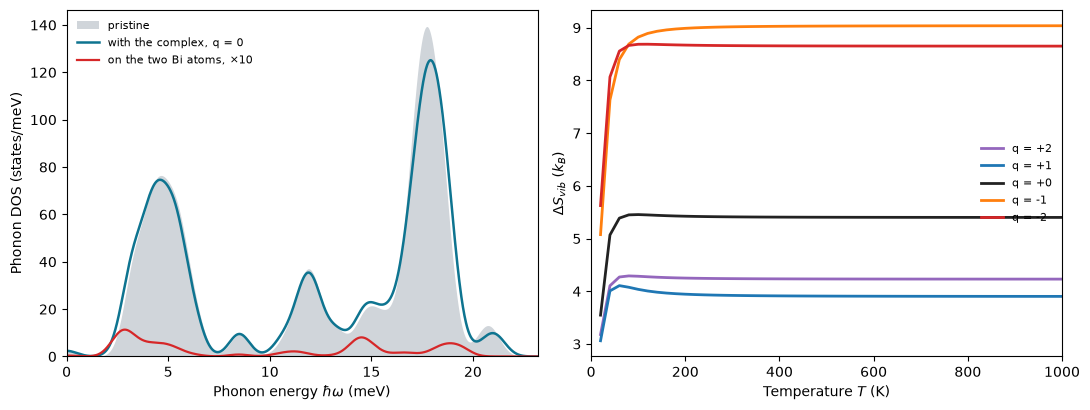

In [5]:
KB = 8.617333e-5


def svib(w, T):
    x = w[w > 1e-4] / (KB * T)
    return np.sum(x / np.expm1(x) - np.log(-np.expm1(-x)))


wp, _ = W["pristine"]
w0, v0 = W[0]
grid = np.linspace(0, 1.08e3 * max(wp.max(), w0.max()), 1200)
dos = lambda w, wt: (wt[None, :] * np.exp(-0.5 * ((grid[:, None] - 1e3 * w[None, :]) / 0.5) ** 2)).sum(1) / (0.5 * np.sqrt(2 * np.pi))
bi = np.array(FC[0][1].get_chemical_symbols()) == "Bi"

T = np.linspace(20, 1000, 50)
dS = {q: np.array([svib(W[q][0], t) - svib(wp, t) for t in T]) for q in cpx}
PAPER = {2: 4.2, 1: 3.9, 0: 5.4, -1: 9.0, -2: 8.7}
for q in sorted(dS, reverse=True):
    print(f"q = {q:+d}: dS_vib = {dS[q][-1]:.1f} k_B at 1000 K, {np.interp(300, T, dS[q]):.1f} k_B at 300 K (paper {PAPER[q]:.1f} k_B)")
for q in (2, 1, 0, -1):
    print(f"({q:+d}/{q - 1:+d}) level shift at 900 K: {-KB * 900 * (np.interp(900, T, dS[q - 1]) - np.interp(900, T, dS[q])):+.2f} eV")

fig, (ax, ae) = plt.subplots(1, 2, figsize=(11, 4.2))
ax.fill_between(grid, dos(wp, np.ones_like(wp)), color="#d0d5da", lw=0, label="pristine")
ax.plot(grid, dos(w0, np.ones_like(w0)), color="#0e7490", lw=1.8, label="with the complex, q = 0")
ax.plot(grid, 10 * dos(w0, v0[bi].sum(0)), color="#d62728", lw=1.6, label="on the two Bi atoms, ×10")
ax.set_xlim(0, grid[-1])
ax.set_ylim(0, None)
ax.set_xlabel(r"Phonon energy $\hbar\omega$ (meV)")
ax.set_ylabel("Phonon DOS (states/meV)")
ax.legend(frameon=False, fontsize=8)
for q, col in zip((2, 1, 0, -1, -2), ["#9467bd", "#1f77b4", "#222222", "#ff7f0e", "#d62728"]):
    ae.plot(T, dS[q], color=col, lw=2, label=f"q = {q:+d}")
ae.set_xlim(0, 1000)
ae.set_xlabel("Temperature $T$ (K)")
ae.set_ylabel(r"$\Delta S_{vib}$ ($k_B$)")
ae.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()